In [1]:
import os
import pandas as pd

# 查看上传的数据文件在哪里
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/kunnyand/olist-logistics-analysis-clea/olist_logistics_analysis.csv


# Olist E-commerce Logistics & Customer Satisfaction Analysis

## 1. Project Overview

This project uses the publicly available Olist Brazilian e-commerce dataset to explore the relationship between delivery delays and customer satisfaction.

**Business Questions**

- How is late delivery associated with negative customer reviews?
- How do bad review rates differ across delivery delay groups?
- Are there regional differences in delivery performance and customer satisfaction?

**Dataset**

The analysis uses 95,824 delivered orders with valid delivery dates and customer review scores.

**Tools:** MySQL, Python, pandas, NumPy, Matplotlib.

**Note:** This is an independent analysis of a public dataset. The findings describe statistical associations rather than causal effects.

In [2]:
import pandas as pd

file_path = "/kaggle/input/datasets/kunnyand/olist-logistics-analysis-clea/olist_logistics_analysis.csv"

df = pd.read_csv(file_path, sep=";")

print("数据维度：", df.shape)
print("唯一订单数：", df["order_id"].nunique())
print("缺失值数量：")
print(df.isna().sum())

display(df.head())

数据维度： (95824, 9)
唯一订单数： 95824
缺失值数量：
order_id          0
purchase_date     0
customer_state    0
delay_days        0
is_late           0
review_score      0
is_bad_review     0
item_count        0
order_amount      0
dtype: int64


,order_id,purchase_date,customer_state,delay_days,is_late,review_score,is_bad_review,item_count,order_amount
0,0197cb265e2c84b9f89dfd784095d2f6,2017-12-21,MS,-33,0,4,0,1,320.00
1,0438fc3e115633e11a93c878a1591016,2018-08-11,BA,-8,0,5,0,1,249.00
2,011b142c9e082a5c1d10e0a88cd9c8e8,2018-03-23,MA,-2,0,5,0,1,243.37
3,01835ef41c5ac66dd9ec6084fa1d0533,2017-05-11,RJ,-9,0,1,1,1,56.99
4,04a59fe46fc5aa341da5378c195ed53c,2017-11-26,PR,-8,0,5,0,1,60.00


## 2. Data Loading & Quality Checks

Before exploring delivery performance and customer satisfaction, we verify the dataset's completeness, order-level uniqueness, and consistency of key business indicators.

The cleaned dataset was prepared using MySQL. Each row represents one order, and negative `delay_days` values indicate delivery before the estimated date.

We also check whether the binary indicators for late delivery and negative reviews are consistent with their original fields.

In [3]:
# 数据类型与日期转换
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

# 数据质量检查
print("Dataset shape:", df.shape)
print("Unique orders:", df["order_id"].nunique())
print("Missing values:", df.isna().sum().sum())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

# 检查标签定义
late_mismatch = (
    df["is_late"] != (df["delay_days"] > 0).astype(int)
).sum()

review_mismatch = (
    df["is_bad_review"] != (df["review_score"] <= 2).astype(int)
).sum()

print("Late indicator mismatches:", late_mismatch)
print("Review indicator mismatches:", review_mismatch)

# 关键业务指标
print("Late delivery rate: {:.2f}%".format(df["is_late"].mean() * 100))
print("Bad review rate: {:.2f}%".format(df["is_bad_review"].mean() * 100))

Dataset shape: (95824, 9)
Unique orders: 95824
Missing values: 0
Duplicate order IDs: 0
Late indicator mismatches: 0
Review indicator mismatches: 0
Late delivery rate: 6.66%
Bad review rate: 12.81%


## 3. Exploratory Data Analysis (EDA)

Before examining the relationship between delivery performance and customer reviews, we explore the distribution of key numerical variables.

The analysis focuses on three variables:

- **delay_days:** Difference between actual and estimated delivery dates. Positive values indicate late delivery.
- **order_amount:** Total product price per order, excluding freight charges.
- **item_count:** Number of order-item records in each order.

We examine summary statistics, percentiles, and skewness to identify potential outliers and understand the characteristics of the dataset.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["delay_days", "order_amount", "item_count"]

summary = df[cols].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(2)

display(summary)

,delay_days,order_amount,item_count
count,95824.00,95824.00,95824.00
mean,-11.91,136.80,1.14
std,10.11,207.79,0.53
min,-147.00,0.85,1.00
25%,-17.00,45.90,1.00
50%,-12.00,86.25,1.00
75%,-7.00,149.90,1.00
90%,-2.00,269.00,1.00
95%,3.00,399.00,2.00
99%,18.00,990.00,3.00


In [5]:
assert len(df) == 95824
assert df["order_id"].is_unique
assert df["is_bad_review"].isin([0, 1]).all()
assert df["is_late"].isin([0, 1]).all()

print("Basic validation passed.")

Basic validation passed.


In [6]:
df["log_amount"] = np.log1p(df["order_amount"])

skew_result = df[
    ["order_amount", "log_amount"]
].agg(["mean", "median", "std", "skew"]).round(2)

display(skew_result)

,order_amount,log_amount
mean,136.80,4.46
median,86.25,4.47
std,207.79,0.92
skew,9.76,0.28


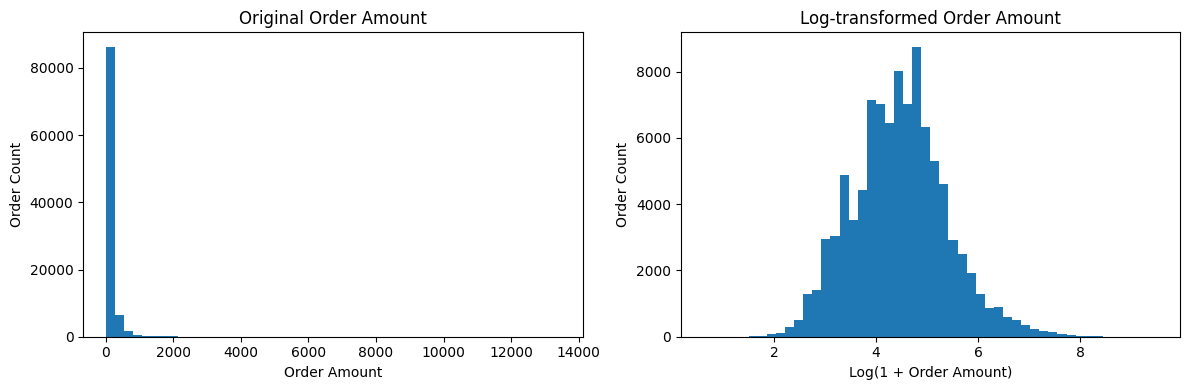

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["order_amount"], bins=50)
axes[0].set_title("Original Order Amount")
axes[0].set_xlabel("Order Amount")
axes[0].set_ylabel("Order Count")

axes[1].hist(df["log_amount"], bins=50)
axes[1].set_title("Log-transformed Order Amount")
axes[1].set_xlabel("Log(1 + Order Amount)")
axes[1].set_ylabel("Order Count")

plt.tight_layout()
plt.show()

### Key Observation: Right-skewed Order Amounts

Order amounts are strongly right-skewed. The mean order amount (136.80) is considerably higher than the median (86.25), while the maximum reaches 13,440.

The skewness decreases from 9.76 to 0.28 after applying `log1p()`, making the distribution more symmetric.

However, high-value orders are not necessarily erroneous observations. We retain the original records and use the transformed amount only when appropriate for subsequent analysis.

The distributional analysis provides context for understanding differences in order characteristics, rather than evidence of a causal relationship with delivery performance.

## 4. Delivery Delays and Negative Reviews

### 4.1 Business Question

How does the negative review rate vary with the length of delivery delays?

To investigate this question, orders are divided into five groups according to the difference between actual and estimated delivery dates.

- **On Time:** Delivered on or before the estimated date.
- **Late 1–3 Days:** Delivered 1–3 days late.
- **Late 4–7 Days:** Delivered 4–7 days late.
- **Late 8–14 Days:** Delivered 8–14 days late.
- **Late 15+ Days:** Delivered at least 15 days late.

A negative review is defined as a customer rating of 1 or 2 stars.

The analysis compares the number of orders, average review score, and negative review rate across these groups.

In [8]:
import numpy as np

conditions = [
    df["delay_days"] <= 0,
    df["delay_days"].between(1, 3),
    df["delay_days"].between(4, 7),
    df["delay_days"].between(8, 14),
    df["delay_days"] >= 15
]

choices = [
    "On Time",
    "Late 1-3 Days",
    "Late 4-7 Days",
    "Late 8-14 Days",
    "Late 15+ Days"
]

df["delay_group"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

print(df["delay_group"].value_counts())

delay_group
On Time           89443
Late 1-3 Days      1852
Late 4-7 Days      1748
Late 8-14 Days     1446
Late 15+ Days      1335
Name: count, dtype: int64


In [9]:
result = df.groupby("delay_group").agg(
    order_count=("order_id", "count"),
    avg_score=("review_score", "mean"),
    low_rate=("is_bad_review", "mean")
)

# 差评率转换为百分数
result["low_rate"] = result["low_rate"] * 100

# 保留两位小数
result = result.round(2)

# 按业务顺序排列
group_order = [
    "On Time",
    "Late 1-3 Days",
    "Late 4-7 Days",
    "Late 8-14 Days",
    "Late 15+ Days"
]

result = result.reindex(group_order)

display(result)

,order_count,avg_score,low_rate
delay_group,,,
On Time,89443,4.29,9.27
Late 1-3 Days,1852,3.29,32.13
Late 4-7 Days,1748,2.10,67.68
Late 8-14 Days,1446,1.67,80.15
Late 15+ Days,1335,1.72,78.35


In [10]:
assert result["order_count"].sum() == len(df)
assert "Unknown" not in df["delay_group"].unique()

print("Delivery group validation passed.")

Delivery group validation passed.


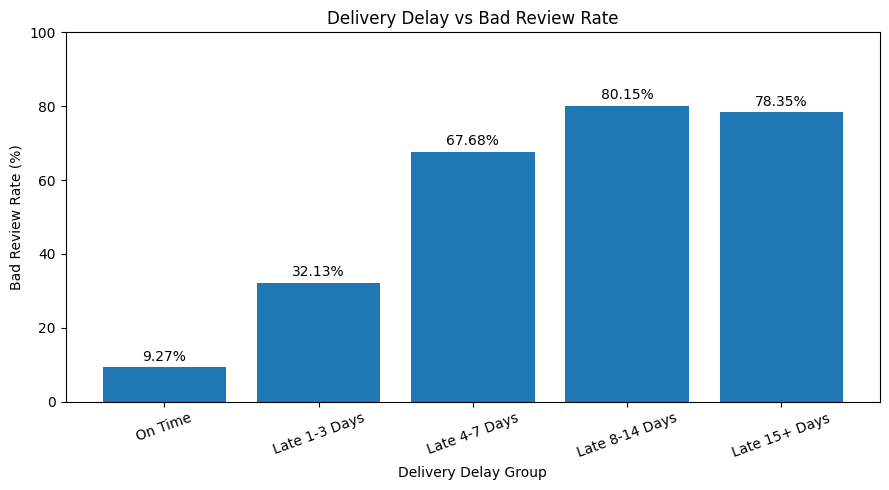

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    result.index,
    result["low_rate"]
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("Delivery Delay vs Bad Review Rate")
ax.set_xlabel("Delivery Delay Group")
ax.set_ylabel("Bad Review Rate (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/01_delivery_bad_review.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.2 Key Findings

The analysis reveals a strong association between delivery delays and negative customer reviews.

- On-time orders have a negative review rate of **9.27%**.
- Orders delayed by 1–3 days have a negative review rate of **32.13%**.
- The rate increases to **67.68%** for delays of 4–7 days.
- Orders delayed by 8–14 days have the highest observed negative review rate at **80.15%**.
- Orders delayed by 15 days or more have a negative review rate of **78.35%**.

Even relatively short delivery delays are associated with substantially higher negative review rates.

However, the relationship is not strictly monotonic, and these descriptive results do not establish causality.

**Business implication:** Early delivery-delay warnings and proactive customer communication may be worth testing as potential strategies to improve customer experience.

## 5. Regional Comparison

### 5.1 Business Question

Are there differences in customer satisfaction between major regions, and does the relationship between delivery delays and negative reviews appear across regions?

We focus on four states with relatively large order volumes: **SP, RJ, MG, and RS**.

For each state, we compare the negative review rate between on-time and late deliveries.

This within-state comparison helps us examine whether the overall association between delivery delays and negative reviews is also observed across different regions.

In [12]:
# 选择四个主要州
states = ["SP", "RJ", "MG", "RS"]

df_state = df[
    df["customer_state"].isin(states)
].copy()

# 按地区、配送状态分组
state_result = (
    df_state.groupby(["customer_state", "is_late"])
    .agg(
        order_count=("order_id", "count"),
        low_rate=("is_bad_review", "mean")
    )
    .reset_index()
)

# 转换为百分数
state_result["low_rate"] = (
    state_result["low_rate"] * 100
).round(2)

display(state_result)

,customer_state,is_late,order_count,low_rate
0,MG,0,10780,9.54
1,MG,1,505,59.01
2,RJ,0,10755,10.92
3,RJ,1,1456,73.08
4,RS,0,5005,8.57
5,RS,1,321,64.17
6,SP,0,38480,8.66
7,SP,1,1786,54.37


In [13]:
plot_data = state_result.pivot(
    index="customer_state",
    columns="is_late",
    values="low_rate"
)

plot_data = plot_data.reindex(states)

plot_data.columns = ["On Time", "Late"]

display(plot_data)

,On Time,Late
customer_state,,
SP,8.66,54.37
RJ,10.92,73.08
MG,9.54,59.01
RS,8.57,64.17


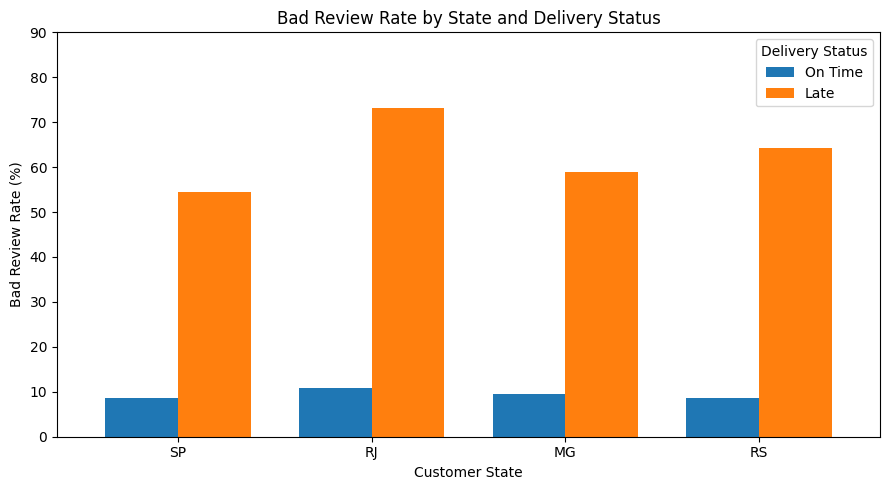

In [14]:
import matplotlib.pyplot as plt

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

ax.set_title("Bad Review Rate by State and Delivery Status")
ax.set_xlabel("Customer State")
ax.set_ylabel("Bad Review Rate (%)")
ax.set_ylim(0, 90)

plt.xticks(rotation=0)
plt.legend(title="Delivery Status")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/02_state_delivery_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Key Findings

Across all four states, late-delivered orders have substantially higher negative review rates than on-time orders.

- **SP:** 8.66% for on-time orders versus 54.37% for late orders.
- **RJ:** 10.92% versus 73.08%.
- **MG:** 9.54% versus 59.01%.
- **RS:** 8.57% versus 64.17%.

RJ has the highest negative review rate among these four states in both delivery groups.

The difference between RJ and SP suggests that regional customer satisfaction patterns cannot be explained by the overall late-delivery rate alone.

However, the analysis does not establish the underlying causes of regional differences. Further investigation could consider product categories, delivery routes, sellers, and customer expectations.

**Business implication:** RJ is a potential priority region for further operational investigation, while delivery-delay management remains relevant across all four states.

In [15]:
# 检查各地区×配送状态的订单数
order_check = state_result.pivot(
    index="customer_state",
    columns="is_late",
    values="order_count"
).reindex(states)

order_check.columns = ["On Time Orders", "Late Orders"]

display(order_check)

# 确认四个州的订单全部参与统计
assert order_check.sum().sum() == len(df_state)

print("Regional analysis validation passed.")

,On Time Orders,Late Orders
customer_state,,
SP,38480,1786
RJ,10755,1456
MG,10780,505
RS,5005,321


Regional analysis validation passed.


## 6. Conclusions & Business Recommendations

### 6.1 Key Findings

This analysis examines 95,824 delivered orders from the Olist Brazilian e-commerce dataset and identifies three key findings.

**Finding 1: Delivery delays are strongly associated with negative reviews.**

The overall late-delivery rate is 6.66%, while the negative review rate is 12.81%.

On-time orders have a negative review rate of 9.27%, compared with 32.13% for orders delayed by 1–3 days and 67.68% for orders delayed by 4–7 days. The negative review rate reaches 80.15% for orders delayed by 8–14 days.

**Finding 2: Customer dissatisfaction varies across regions.**

Across SP, RJ, MG, and RS, late-delivered orders consistently have higher negative review rates than on-time orders.

RJ has the highest negative review rate among these four states in both delivery groups. Its late-delivery negative review rate is 73.08%, compared with 54.37% in SP.

**Finding 3: Short delivery delays deserve attention.**

Even relatively short delays of 1–3 days are associated with a substantially higher negative review rate than on-time deliveries.

This suggests that early-stage delivery warnings and customer communication may be useful areas for operational experimentation.

### 6.2 Business Recommendations

**Recommendation 1: Establish early delivery-delay alerts.**

Identify orders approaching their estimated delivery dates and prioritize proactive communication when delays are likely.

**Recommendation 2: Investigate regional differences.**

Prioritize further investigation of RJ, including delivery routes, logistics partners, product categories, and order characteristics.

**Recommendation 3: Evaluate interventions before scaling.**

Test selected customer communication or logistics interventions on a limited scale. Assess their impact on customer satisfaction alongside operational costs.

### 6.3 Limitations

This analysis uses a historical public dataset and includes only delivered orders with valid delivery dates and review scores.

The findings describe statistical associations and do not establish that delivery delays cause negative reviews.

Other factors, including product quality, seller performance, delivery distance, and customer expectations, may also influence satisfaction.

The recommended actions are hypotheses for future testing rather than proven business improvements.

### 6.4 Reproducibility

All summary statistics and visualizations in this notebook are generated from the attached cleaned CSV dataset.

The source data originates from the public Olist Brazilian e-commerce dataset. Data preprocessing was performed separately in MySQL 8.0.

This notebook reproduces the Python analysis; the upstream SQL cleaning scripts are required for full end-to-end reproduction from the original tables.

---

**Project Type:** Independent portfolio project using publicly available e-commerce data.

**Tools:** MySQL 8.0, Python, pandas, NumPy, and Matplotlib.

In [16]:
# Final reproducibility checks

assert len(df) == 95824
assert df["order_id"].is_unique
assert df.isna().sum().sum() == 0

assert df["is_late"].mean() * 100 > 6.6
assert df["is_late"].mean() * 100 < 6.7

assert df["is_bad_review"].mean() * 100 > 12.8
assert df["is_bad_review"].mean() * 100 < 12.9

assert result["order_count"].sum() == len(df)

assert order_check.sum().sum() == len(df_state)

print("All reproducibility checks passed!")

All reproducibility checks passed!
